# Лабораторная работа № 2.  
## *Аугментация данных и устойчивость ASR*

Цель работы: понять, как контролируемые детерминированные изменения сигнала влияют на одну небольшую локальную модель распознавания речи.

In [1]:
import sys
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Image, display

LAB_DIR = Path.cwd()
AUG_DIR = LAB_DIR / "outputs" / "augmented"
FIG_DIR = LAB_DIR / "outputs" / "figures"
RES_DIR = LAB_DIR / "outputs" / "results"
sys.path.insert(0, str(LAB_DIR / "scripts"))
from plot_augmentation_features import log_mel, specaugment

SR = 16_000
ITEM = "1272-128104-0000"

per_item = pd.read_csv(RES_DIR / "per_item_results.csv")
aggregate = pd.read_csv(RES_DIR / "aggregate_results.csv")


def load_audio(item_id, condition):
    audio, _ = librosa.load(AUG_DIR / f"{item_id}__{condition}.wav", sr=SR, mono=True)
    return audio


def plot_conditions(item_id, conditions):
    fig, axes = plt.subplots(len(conditions), 2, figsize=(14, 3.2 * len(conditions)))
    for row, condition in enumerate(conditions):
        audio = load_audio(item_id, condition)
        librosa.display.waveshow(audio, sr=SR, ax=axes[row, 0])
        axes[row, 0].set_ylim(-1, 1)
        axes[row, 0].set_title(f"{condition}: waveform")
        image = librosa.display.specshow(log_mel(audio, SR), sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=axes[row, 1], cmap="viridis", vmin=-80, vmax=0)
        axes[row, 1].set_title(f"{condition}: log-Mel")
        fig.colorbar(image, ax=axes[row, 1], format="%+2.0f dB")
    fig.tight_layout()
    plt.show()


## Задание 1

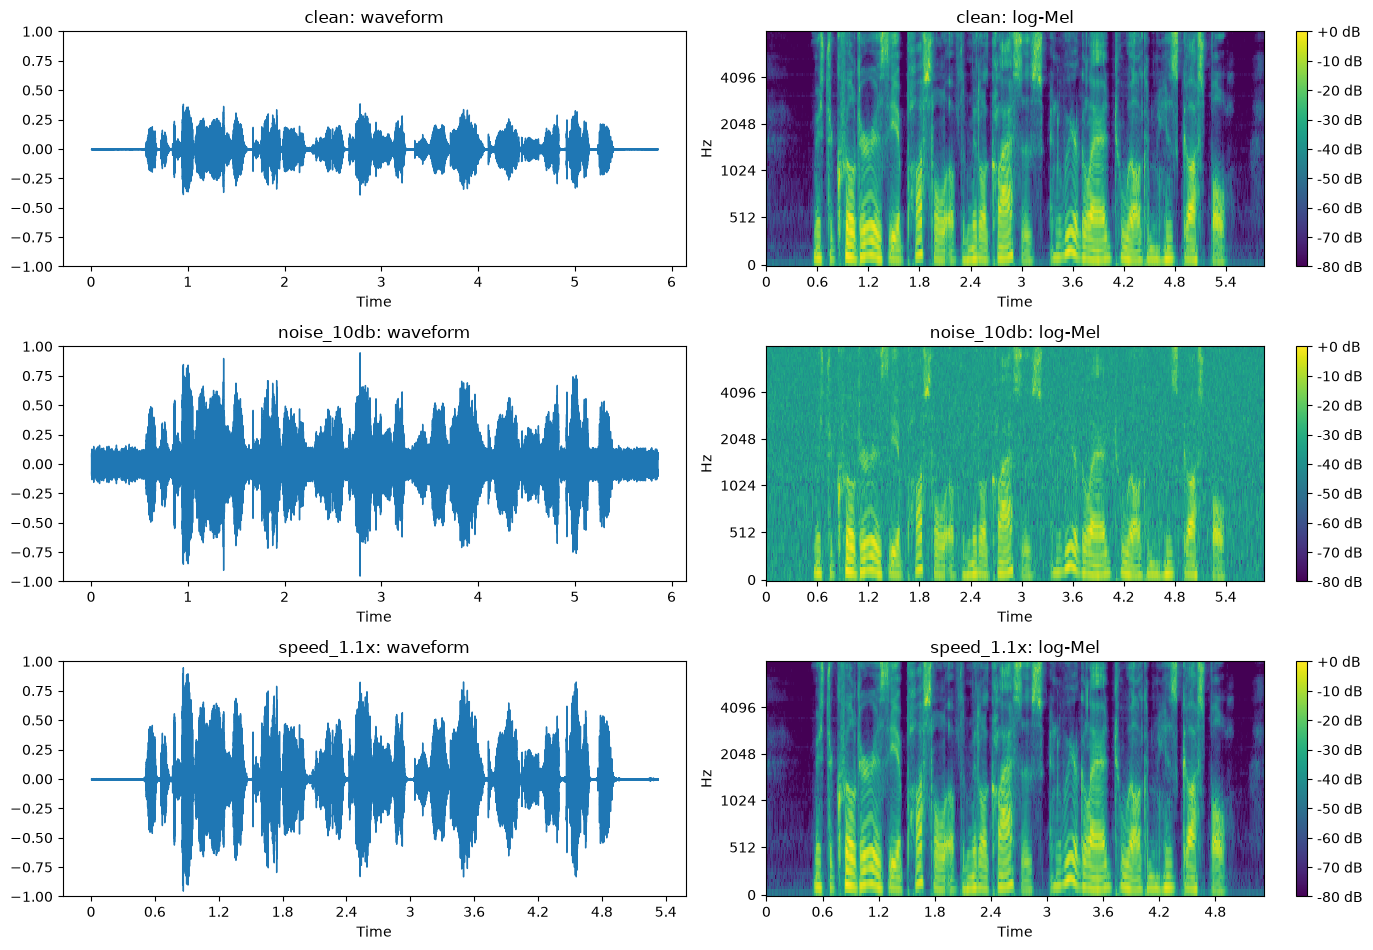

In [2]:
plot_conditions(ITEM, ["clean", "noise_10db", "speed_1.1x"])

In [3]:
rows = []
for condition in ["clean", "noise_10db", "speed_1.1x"]:
    audio = load_audio(ITEM, condition)
    mel = log_mel(audio, SR)
    rows.append({
        "condition": condition,
        "seconds": len(audio) / SR,
        "peak": np.abs(audio).max(),
        "rms": np.sqrt(np.mean(audio**2)),
        "quiet_floor_db": np.percentile(mel, 5),
        "high_band_mean_db": mel[60:].mean(),
    })
pd.DataFrame(rows).round(3)

,condition,seconds,peak,rms,quiet_floor_db,high_band_mean_db
0,clean,5.855,0.388,0.062,-80.000000,-54.320999
1,noise_10db,5.855,0.950,0.146,-41.886002,-34.396999
2,speed_1.1x,5.323,0.950,0.153,-80.000000,-55.814999


аугментации:
- аддитивный шум и изменение скорости.

что видно на волновой форме:
- у шума пауза в начале и в конце не плоская, там появилась широкая полоса помех.
- у ускорения пауза остаётся плоской. форма слов сохранилась, но вся запись стала короче.

что видно на log-Mel:
- у шума тёмные области без энергии стали светлыми, особенно сильно залиты высокие частоты и паузы.
яркие гармоники в нижней части остались. слабые согласные в верхней части потерялись в фоне.
- у ускорения картина та же, но она сжата по времени. рисунок гармоник стал плотнее, а форманты немного сместились вверх по частоте.

## Задание 2

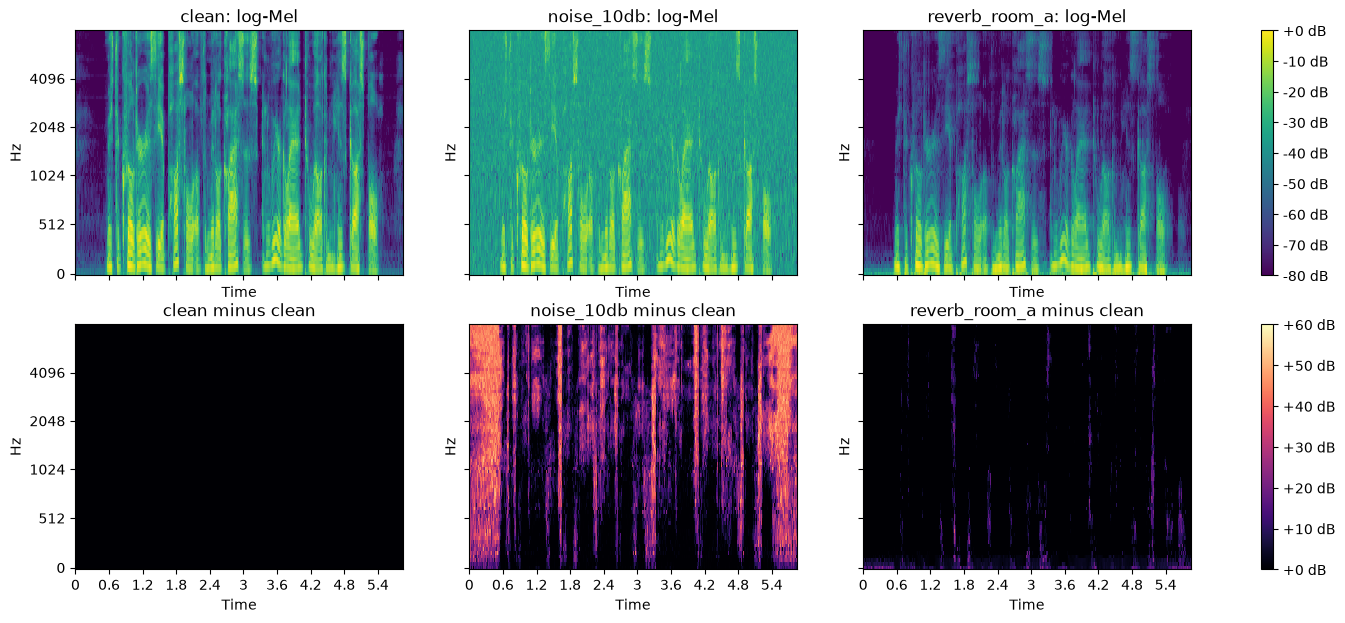

In [4]:
clean_mel = log_mel(load_audio(ITEM, "clean"), SR)
fig, axes = plt.subplots(2, 3, figsize=(18, 7), sharex=True, sharey=True)
for column, condition in enumerate(["clean", "noise_10db", "reverb_room_a"]):
    mel = log_mel(load_audio(ITEM, condition), SR)
    image = librosa.display.specshow(mel, sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=axes[0, column], cmap="viridis", vmin=-80, vmax=0)
    axes[0, column].set_title(f"{condition}: log-Mel")
    diff = mel - clean_mel
    diff_image = librosa.display.specshow(diff, sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=axes[1, column], cmap="magma", vmin=0, vmax=60)
    axes[1, column].set_title(f"{condition} minus clean")
fig.colorbar(image, ax=axes[0, :], format="%+2.0f dB")
fig.colorbar(diff_image, ax=axes[1, :], format="%+2.0f dB")
plt.show()

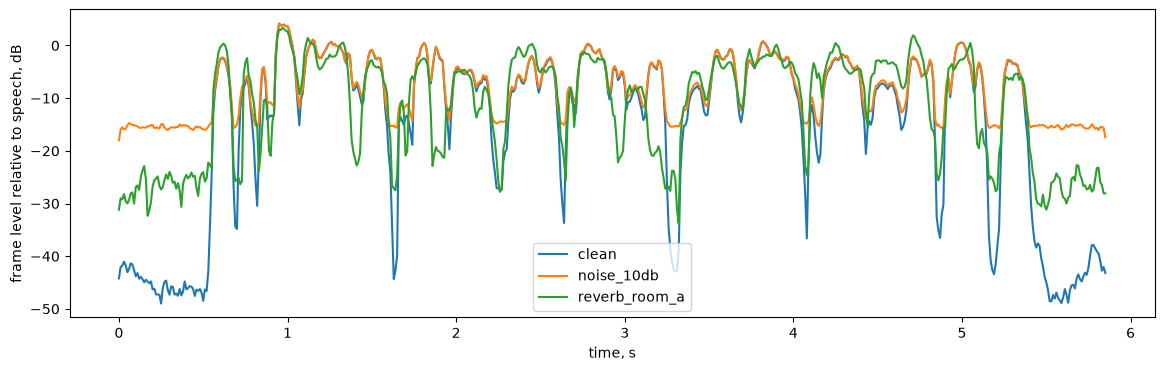

In [5]:
def envelope_db(audio):
    rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)[0]
    db = 20 * np.log10(rms + 1e-8)
    return db - np.percentile(db, 95)


clean_env = envelope_db(load_audio(ITEM, "clean"))
times = librosa.frames_to_time(np.arange(len(clean_env)), sr=SR, hop_length=160)
fig, ax = plt.subplots(figsize=(14, 4))
for condition in ["clean", "noise_10db", "reverb_room_a"]:
    ax.plot(times, envelope_db(load_audio(ITEM, condition)), label=condition)
ax.set_xlabel("time, s")
ax.set_ylabel("frame level relative to speech, dB")
ax.legend()
plt.show()

что показывает разностная карта:
- шум поднимает уровень почти равномерно везде, где чистый сигнал был тихим. это особенно заметно на высоких частотах и в паузах, подъём не зависит от того, что звучало раньше.
- реверберация поднимает уровень не везде. подъём идёт узкими вертикальными полосами сразу после громких событий, значит, добавляется не посторонний фон, а затухающая копия самого сигнала.

что показывает огибающая:
- у шума пауза лежит на ровной полке. начало и конец записи имеют один и тот же уровень.
- у реверберации спады после слов затянуты. провалы между словами меньше, чем в чистом сигнале, а фронты слов при этом остаются на своих местах, но их края стали мягче.

выводы:
- маскирование добавляет независимый фон и закрывает слабые участки.
- временное размытие размазывает энергию слова по времени.
- у шума пол одинаков по всей записи, а у реверберации хвосты следуют за словами.

## Задание 3

In [6]:
rows = []
for item_id in sorted(per_item["item_id"].unique()):
    original = sf.info(LAB_DIR / "data" / "wav" / f"{item_id}.wav").duration
    row = {"item_id": item_id, "original_s": original}
    for condition in ["speed_0.9x", "speed_1.1x"]:
        seconds = sf.info(AUG_DIR / f"{item_id}__{condition}.wav").duration
        row[f"{condition}_s"] = seconds
        row[f"{condition}_ratio"] = seconds / original
    rows.append(row)
durations = pd.DataFrame(rows)
display(durations.round(3))
durations[["speed_0.9x_ratio", "speed_1.1x_ratio"]].mean().round(3)

,item_id,original_s,speed_0.9x_s,speed_0.9x_ratio,speed_1.1x_s,speed_1.1x_ratio
0,1272-128104-0000,5.855,6.506,1.111,5.323,0.909
1,1272-128104-0001,4.815,5.350,1.111,4.377,0.909
2,1272-128104-0003,9.900,11.000,1.111,9.000,0.909
3,1272-128104-0006,5.640,6.267,1.111,5.127,0.909
4,1272-128104-0007,9.240,10.267,1.111,8.400,0.909


speed_0.9x_ratio    1.111
speed_1.1x_ratio    0.909
dtype: float64

In [7]:
aggregate[aggregate["condition"].isin(["clean", "speed_0.9x", "speed_1.1x"])][["condition", "mean_wer", "mean_cer", "mean_rtf"]]

,condition,mean_wer,mean_cer,mean_rtf
0,clean,0.103958,0.059503,0.119969
5,speed_0.9x,0.083958,0.049979,0.117961
6,speed_1.1x,0.087291,0.054097,0.128870


как фактор влияет на длительность:
- фактор < 1 растягивает запись.
- фактор > 1 сжимает запись.

почему длительности недостаточно:
- в реализации скорость меняется через передискретизацию, вместе с темпом меняется и высота тона, и положение формант.
- модель реагирует на спектр и на темп вместе, а не на длительность сама по себе.
- замедление и ускорение дали близкий результат, обачуть лучше чистого сигнала.
- если бы длительность определяла качество, два противоположных изменения дали бы разный эффект.
- на пяти фразах разница в один-два слова меняет метрику сильнее, чем скорость, поэтому по длительности нельзя предсказать поведение WER.

## Задание 4

mask metadata: {'time_start': 281, 'time_width': 24, 'frequency_start': 35, 'frequency_width': 10}
time mask, s: 2.81 to 3.05
frequency mask, Hz: 1399 to 1978
total duration, s: 5.86


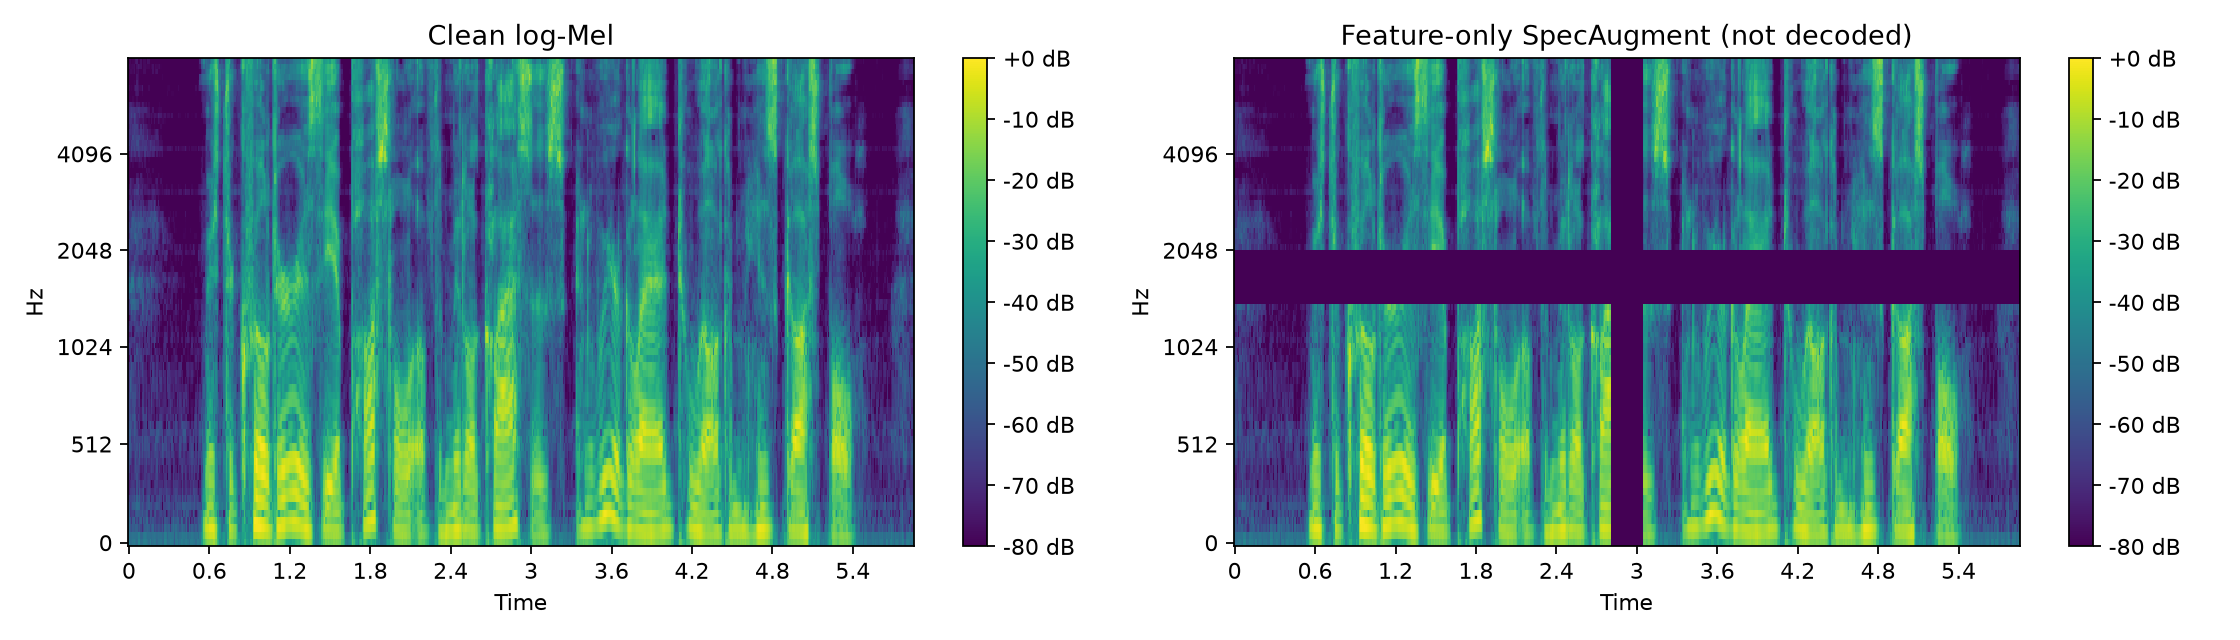

In [8]:
clean_mel = log_mel(load_audio(ITEM, "clean"), SR)
masked, meta = specaugment(clean_mel)
mel_hz = librosa.mel_frequencies(n_mels=80, fmin=20, fmax=7600)
print("mask metadata:", meta)
print("time mask, s:", meta["time_start"] * 160 / SR, "to", (meta["time_start"] + meta["time_width"]) * 160 / SR)
print("frequency mask, Hz:", round(mel_hz[meta["frequency_start"]]), "to", round(mel_hz[meta["frequency_start"] + meta["frequency_width"] - 1]))
print("total duration, s:", clean_mel.shape[1] * 160 / SR)
display(Image(filename=FIG_DIR / "specaugment_feature_only.png"))

какие области скрыты:
- временная маска это вертикальная полоса в середине записи, она закрывает короткий отрезок около третьей секунды по всем частотам.
- частотная маска это горизонтальная полоса в средней части диапазона, она закрывает полосу в районе второго формантного диапазона речи, на всём протяжении записи.
- обе маски залиты минимальным значением спектрограммы.

почему это полезно при обучении:
- модель не может опираться на один узкий участок спектра или одно мгновение, ей приходится использовать контекст.
- соседние кадры и другие частоты помогают восстановить пропущенное. +это похоже на реальные потери: короткий щелчок, провал канала, полосовой шум.
- такая аугментация дёшево увеличивает разнообразие данных и снижает переобучение: она не требует нового аудио и не меняет саму запись.

## Задание 5

In [9]:
EXAMPLE = "1272-128104-0001"
example = per_item[(per_item["item_id"] == EXAMPLE) & per_item["condition"].isin(["clean", "reverb_room_a", "noise_0db"])]
table = example[["condition", "wer", "cer", "rtf", "decode_seconds", "audio_seconds"]].set_index("condition")
display(table.round(3))
print("reference:", example.iloc[0]["reference_raw"])
for _, row in example.iterrows():
    print(f"{row['condition']:>14}: {row['hypothesis_raw']}")

,wer,cer,rtf,decode_seconds,audio_seconds
condition,,,,,
clean,0.2,0.111,0.178,0.858,4.815
noise_0db,0.8,0.302,0.774,3.728,4.815
reverb_room_a,0.3,0.143,0.161,0.775,4.815


reference: NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER
         clean: Nor is Mr. Colter's manner less interesting than his matter.
     noise_0db: Norers, Mr. Quotley's man, are less interesting than who's met her.
 reverb_room_a: Nor is Mr. Coulter's matter less interesting than his matter.


In [10]:
relative = table[["wer", "cer", "rtf"]].div(table.loc["clean", ["wer", "cer", "rtf"]], axis=1)
relative.round(2)

,wer,cer,rtf
condition,,,
clean,1.0,1.00,1.00
noise_0db,4.0,2.71,4.35
reverb_room_a,1.5,1.29,0.90


выбрано:
- вторая фраза про манеру мистера Квилтера. 
- сравниваются чистый сигнал, реверберация `room_a` и шум нулевого уровня.

анализ:
- чистый сигнал даёт среднюю ошибку: имя Квилтер распознано как созвучное слово.
- реверберация добавляет ещё одну ошибку. слово «manner» превратилось в «matter».
- шум нулевого уровня разрушает почти всю фразу, остаются только отдельные слова.

какая метрика меняется сильнее всего:
- RTF при шуме, WER растёт почти так же сильно. CER растёт сильно слабее WER.
- при реверберации RTF немного падает, а WER и CER растут умеренно.

почему:
- RTF показывает время работы декодера, а не качество. при тяжёлом шуме модель повторяет попытки декодирования и дольше строит гипотезу.
- сильнее всего меняется WER: одна неверная буква делает неверным всё слово, а CER считает только символы.
RTF к тому же зависит от нагрузки машины, поэтому на одной фразе ему нельзя верить.

## Задание 6

In [11]:
ranked = aggregate.sort_values("mean_wer", ascending=False)
display(ranked.round(3))
worst = ranked.iloc[0]
print("worst condition:", worst["condition"], "mean_wer:", round(worst["mean_wer"], 3), "mean_cer:", round(worst["mean_cer"], 3))
for item_id in ["1272-128104-0003", "1272-128104-0006"]:
    clean_row = per_item[(per_item["item_id"] == item_id) & (per_item["condition"] == "clean")].iloc[0]
    worst_row = per_item[(per_item["item_id"] == item_id) & (per_item["condition"] == worst["condition"])].iloc[0]
    print()
    print("item:     ", item_id)
    print("reference:", worst_row["reference_normalized"])
    print("clean:    ", clean_row["hypothesis_normalized"], f"(wer {clean_row['wer']:.3f})")
    print("worst:    ", worst_row["hypothesis_normalized"], f"(wer {worst_row['wer']:.3f})")

,condition,utterance_count,reference_word_count,mean_wer,mean_cer,mean_rtf
1,noise_0db,5,82,0.644,0.363,0.212
2,noise_10db,5,82,0.149,0.082,0.129
4,reverb_room_a,5,82,0.141,0.070,0.122
3,noise_20db,5,82,0.129,0.070,0.125
0,clean,5,82,0.104,0.060,0.120
6,speed_1.1x,5,82,0.087,0.054,0.129
5,speed_0.9x,5,82,0.084,0.050,0.118


worst condition: noise_0db mean_wer: 0.644 mean_cer: 0.363

item:      1272-128104-0003
reference: he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca
clean:     he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca (wer 0.042)
worst:     he has great notes for that so he's going to make him work with me he's beat after all and he can discover in it a little while he isn't hurt (wer 0.833)

item:      1272-128104-0006
reference: on the general principles of art mister quilter writes with equal lucidity
clean:     on the general principles of art mr krilter writes with equal lucidity (wer 0.167)
worst:     and the general principles of art and mr crother writes that people receive a key (wer 0.750)


самый сильный вариант:
- `noise_0db`, то есть шум с мощностью, равной мощности речи.
- `mean_wer` и `mean_cer` намного выше, чем у любого другого варианта.
- остальные варианты лежат близко к чистому сигналу.

сравнение текстов (1 фраза):
- эталон: «he has grave doubts ... but little of rocky ithaca».
- при шуме: «he has great notes for that so he's going to make him work with me ...».

сравнение текстов (2 фраза):
- эталон: «on the general principles of art mister quilter»
- результат: «and the general principles of art and mr crother».

почему этот вариант самый сильный:
- белый шум с равной мощностью закрывает слабые согласные и высокие частоты, которые несут различие между словами.
- остаётся в основном низкочастотная энергия гласных, по которой не определить слово.
- остальные аугментации сохраняют структуру речи. шум хуже всего потому, что он перекрывает информацию, а не искажает её.

## Задание 7

In [12]:
clean_row = aggregate[aggregate["condition"] == "clean"].iloc[0]
gap = aggregate[aggregate["condition"] != "clean"][["condition", "mean_wer", "mean_cer"]].copy()
gap["wer_growth"] = gap["mean_wer"] / clean_row["mean_wer"] - 1
gap["cer_growth"] = gap["mean_cer"] / clean_row["mean_cer"] - 1
gap["growth_difference"] = gap["wer_growth"] - gap["cer_growth"]
gap.sort_values("growth_difference", ascending=False).round(3)

,condition,mean_wer,mean_cer,wer_growth,cer_growth,growth_difference
4,reverb_room_a,0.141,0.070,0.353,0.183,0.170
1,noise_0db,0.644,0.363,5.199,5.098,0.101
3,noise_20db,0.129,0.070,0.240,0.177,0.064
2,noise_10db,0.149,0.082,0.433,0.374,0.058
5,speed_0.9x,0.084,0.050,-0.192,-0.160,-0.032
6,speed_1.1x,0.087,0.054,-0.160,-0.091,-0.069


In [13]:
for item_id in ["1272-128104-0001", "1272-128104-0003"]:
    subset = per_item[(per_item["item_id"] == item_id) & per_item["condition"].isin(["clean", "reverb_room_a"])]
    print("reference:", subset.iloc[0]["reference_normalized"])
    for _, row in subset.iterrows():
        print(f"{row['condition']:>14}: {row['hypothesis_normalized']}  wer={row['wer']:.3f} cer={row['cer']:.3f}")
    print()

reference: nor is mister quilter's manner less interesting than his matter
         clean: nor is mr colter's manner less interesting than his matter  wer=0.200 cer=0.111
 reverb_room_a: nor is mr coulter's matter less interesting than his matter  wer=0.300 cer=0.143

reference: he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca
         clean: he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca  wer=0.042 cer=0.030
 reverb_room_a: he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of wonky ithaka  wer=0.125 cer=0.053



выбранный тип:
- реверберация `room_a`.
- рост WER больше, чем рост CER.

что видно в текстах:
- в одном случае «manner» заменено на «matter». слово одно, разница в нескольких символах.
- в другом случае «rocky ithaca» стало «wonky ithaka». замена слова + слово с другой орфографией.

почему так:
- WER считает слово целиком: любая замена одной буквы даёт полную ошибку слова.
- CER считает символы, поэтому та же замена почти не заметна на фоне длинной фразы.
- реверберация портит отдельные соседние звуки и границы слов, но не разрушает всю фразу, поэтому ошибки редкие и точечные.

## Задание 8

In [14]:
markers = [
    ("1272-128104-0007", "more effect", "reference: more fact"),
    ("1272-128104-0003", "layton", "reference: leighton"),
    ("1272-128104-0003", "wonky", "reference: rocky"),
    ("1272-128104-0003", "great doubts", "reference: grave doubts"),
    ("1272-128104-0001", "matter less", "reference: manner less"),
]
rows = []
for item_id, marker, note in markers:
    subset = per_item[per_item["item_id"] == item_id]
    hit = subset[subset["hypothesis_normalized"].str.contains(marker)]
    rows.append({"item_id": item_id, "error_marker": marker, "note": note, "hit_conditions": ", ".join(hit["condition"])})
pd.DataFrame(rows)

,item_id,error_marker,note,hit_conditions
0,1272-128104-0007,more effect,reference: more fact,"clean, noise_20db, noise_10db, noise_0db, reve..."
1,1272-128104-0003,layton,reference: leighton,"clean, noise_20db, reverb_room_a, speed_0.9x, ..."
2,1272-128104-0003,wonky,reference: rocky,"noise_20db, noise_10db, reverb_room_a"
3,1272-128104-0003,great doubts,reference: grave doubts,"noise_20db, noise_10db"
4,1272-128104-0001,matter less,reference: manner less,"noise_10db, reverb_room_a"


In [15]:
reference_row = per_item[(per_item["item_id"] == "1272-128104-0003") & (per_item["condition"] == "clean")].iloc[0]
print(f"{'reference':>14}: {' '.join(reference_row['reference_normalized'].split()[-8:])}")
for condition in ["clean", "noise_20db", "noise_10db", "reverb_room_a", "speed_1.1x"]:
    row = per_item[(per_item["item_id"] == "1272-128104-0003") & (per_item["condition"] == condition)].iloc[0]
    print(f"{condition:>14}: {' '.join(row['hypothesis_normalized'].split()[-8:])}")

     reference: discover in it but little of rocky ithaca
         clean: discover in it but little of rocky ithaca
    noise_20db: discover in it but little of wonky ichaka
    noise_10db: discover in it but little of wonky essica
 reverb_room_a: discover in it but little of wonky ithaka
    speed_1.1x: discover in it but little of rocky ithaca


повторяющиеся ошибки:
1. эталон «more fact», гипотеза «more effect». ошибка есть во всех условиях, включая чистый сигнал.
2. эталон «leighton», гипотеза «layton». ошибка есть и в чистом сигнале, и в большинстве аугментаций.
3. эталон «rocky ithaca», гипотеза «wonky ithaca» в разных написаниях. ошибка есть при слабом и среднем шуме и при реверберации, но нет в чистом сигнале и при изменении скорости.
4. эталон «grave doubts», гипотеза «great doubts». ошибка есть при шуме двух умеренных уровней.

возможные объяснения:
- первые две ошибки есть уже в чистом сигнале.
- третья ошибка появляется только при шуме и реверберации. мб начальный звук «r» слабый, и фон его перекрывает.
- четвёртая ошибка появляется только при шуме. «v» слабый, и шум его закрывает.

## Задание 9

In [16]:
summary = per_item.groupby("condition").agg(utterances=("item_id", "nunique"), mean_wer=("wer", "mean"), wer_std=("wer", "std"))
display(summary.round(3))
total_words = aggregate.loc[aggregate["condition"] == "clean", "reference_word_count"].iloc[0]
print("reference words in the whole benchmark:", total_words)
print("share of one word:", round(1 / total_words, 4))
display(per_item[per_item["condition"] == "clean"][["item_id", "wer", "cer"]].round(3))

,utterances,mean_wer,wer_std
condition,,,
clean,5,0.104,0.074
noise_0db,5,0.644,0.211
noise_10db,5,0.149,0.101
noise_20db,5,0.129,0.068
reverb_room_a,5,0.141,0.101
speed_0.9x,5,0.084,0.051
speed_1.1x,5,0.087,0.065


reference words in the whole benchmark: 82
share of one word: 0.0122


,item_id,wer,cer
0,1272-128104-0000,0.059,0.045
7,1272-128104-0001,0.200,0.111
14,1272-128104-0003,0.042,0.030
21,1272-128104-0006,0.167,0.081
28,1272-128104-0007,0.053,0.030


нет, более высокий WER не означает, что аугментация универсально ломает ASR.

1 вариант: маленькая выборка:
- одно слово заметно меняет метрику.
- разброс между фразами внутри одного условия сопоставим с разницей между условиями, исключение составляет только самый сильный шум.
- часть ошибок вообще не связана с аугментацией.

2 вариант: одна маленькая модель:
- мб более крупная модель вела бы себя иначе.